# Model ablation analysis

What drives VLM's goal-dependent behavior?

Two ablations of the search prompt:

- **goal ablation** — the tokens of the goal sentence (*"You are searching for a {target} in this image …"*) cannot attend to the image tokens at any layer.
- **control ablation** — a size-matched control: the tokens of the answer-format sentence cannot attend to the image tokens.

Each run is scored per image with three metrics: Pearson CC of the model's density map with the human
search map (`cc_search`), with the human free-view map (`cc_free`), and with the model's own
free-view-prompt map (`vs free-view output`). 

In [2]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

In [3]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
from scipy import stats

# analysis/ is the parent of notebooks/
ANALYSIS = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ANALYSIS))
from helpers import runs as R, util as U
U.apply_figstyle()
from helpers.util import gm
print("data dir:", R.DATA_DIR)
MODELS = ["qwen-instruct", "gemma"]
CONDITIONS = ["tp", "ta"]
# display name -> ablation key in helpers.runs.ABLATIONS
ABLATION_KEYS = {"Control Ablation": "format", "Goal Ablation": "goal"}
ABLATION_RUNS = list(ABLATION_KEYS)
HUMAN_MAPS = {"cc_search": "Human search", "cc_free": "Human free-view"}

data dir: /Users/hanzh/Documents/Github/VLM-goal-directed-attention/analysis/data


## Runs

In [4]:
# The runs scored per model (qwen/gemma) and condition (tp/ta): the two ablations and the free-view-prompt run
rows = []
for model in MODELS:
    for condition in CONDITIONS:
        rows += [
            *[{"model": model, "condition": condition, "run": run, "ids": U.get_ablation_run_ids(model, condition, key)}
              for run, key in ABLATION_KEYS.items()],
            {"model": model, "condition": condition, "run": "free-view", "ids": U.get_run_ids(model, condition, "free")},
        ]
pd.DataFrame(rows)

,model,condition,run,ids
0,qwen-instruct,tp,Control Ablation,"[63953880, 63998068]"
1,qwen-instruct,tp,Goal Ablation,"[63953881, 63998069]"
2,qwen-instruct,tp,free-view,"[63889208, 63889209]"
3,qwen-instruct,ta,Control Ablation,"[63953876, 63998066]"
4,qwen-instruct,ta,Goal Ablation,"[63953877, 63998067]"
5,qwen-instruct,ta,free-view,"[63889204, 63889205]"
6,gemma,tp,Control Ablation,"[64279304, 64348378, 64348381]"
7,gemma,tp,Goal Ablation,"[64279305, 64317440]"
8,gemma,tp,free-view,"[58411643, 58387156]"
9,gemma,ta,Control Ablation,"[64279302, 64317437]"


## Per-image scores

In [5]:
def score_cell(model, condition):
    """Per-image cc_search / cc_free / CC-with-free-view for the two ablated runs."""
    ablated = {run: U.density_maps_from_points(
                   U.load_fixations(U.get_ablation_run_ids(model, condition, key), mode="vlm"), mode="vlm")
               for run, key in ABLATION_KEYS.items()}
    freeview_ids = U.get_run_ids(model, condition, "free")
    freeview = U.density_maps_from_points(U.load_fixations(freeview_ids, mode="vlm"), mode="vlm")
    human = U.load_fixations(freeview_ids, mode="human")
    human_search = U.density_maps_from_points(human, mode="human", goal="search")
    human_free = U.density_maps_from_points(human, mode="human", goal="free")

    # images present in both ablations, the free-view run and both human maps
    keys = sorted(set.intersection(*[set(m) for m in ablated.values()]) & set(freeview)
                  & set(human_search) & set(human_free))
    records = []
    for key in keys:
        for run in ABLATION_RUNS:
            m = ablated[run][key]
            records.append({
                "model": model, "condition": condition, "run": run, "task": key[0], "name": key[1],
                "cc_search": gm.cc(m, human_search[key]),
                "cc_free": gm.cc(m, human_free[key]),
                "vs_freeview": gm.cc(m, freeview[key]),
            })
    print(f"{model} {condition}: {len(keys)} images")
    return pd.DataFrame(records)


scores = pd.concat([score_cell(model, condition) for model in MODELS for condition in CONDITIONS],
                   ignore_index=True)
scores.head()

qwen-instruct tp: 2474 images
qwen-instruct ta: 2413 images
gemma tp: 2474 images
gemma ta: 2347 images


,model,condition,run,task,name,cc_search,cc_free,vs_freeview
0,qwen-instruct,tp,Control Ablation,bottle,000000001455.jpg,0.950752,0.080579,0.412692
1,qwen-instruct,tp,Goal Ablation,bottle,000000001455.jpg,0.461149,0.315120,0.698255
2,qwen-instruct,tp,Control Ablation,bottle,000000009527.jpg,0.782896,0.368919,0.089993
3,qwen-instruct,tp,Goal Ablation,bottle,000000009527.jpg,0.435530,0.704975,0.716361
4,qwen-instruct,tp,Control Ablation,bottle,000000018658.jpg,0.838246,0.092810,0.473610


## Cell means

In [6]:
METRICS = ["cc_search", "cc_free", "vs_freeview"]

cell_means = (
    scores.groupby(["model", "condition", "run"], sort=False)[METRICS]
    .mean()
    .join(scores.groupby(["model", "condition", "run"], sort=False).size().rename("n"))
    .reset_index()
)
cell_means["run"] = pd.Categorical(cell_means["run"], ABLATION_RUNS)
cell_means.sort_values(["model", "condition", "run"]).round(3)

,model,condition,run,cc_search,cc_free,vs_freeview,n
6,gemma,ta,Control Ablation,0.393,0.233,0.278,2347
7,gemma,ta,Goal Ablation,0.382,0.355,0.467,2347
4,gemma,tp,Control Ablation,0.703,0.166,0.361,2474
5,gemma,tp,Goal Ablation,0.457,0.358,0.557,2474
2,qwen-instruct,ta,Control Ablation,0.475,0.255,0.293,2413
3,qwen-instruct,ta,Goal Ablation,0.408,0.414,0.588,2413
0,qwen-instruct,tp,Control Ablation,0.716,0.168,0.355,2474
1,qwen-instruct,tp,Goal Ablation,0.402,0.419,0.634,2474


## Statistics

**Panel A** — per model × condition, a 2×2 repeated-measures ANOVA over images with within-image factors
ablation (Control, Goal) × human map (search, free-view), followed by paired pairwise tests of Goal vs
Control within each human map. **Panel B** — per model × condition, a paired t-test of Goal vs Control on
the CC with the model's own free-view output. Effect sizes are Cohen's d (pingouin).

In [7]:
scores["image"] = scores["task"] + "/" + scores["name"]
long = scores.melt(id_vars=["model", "condition", "run", "image"], value_vars=list(HUMAN_MAPS),
                   var_name="human_map", value_name="cc")
long["human_map"] = long["human_map"].map(HUMAN_MAPS)

anova_rows, pairwise_rows = [], []
for (model, condition), cell in long.groupby(["model", "condition"], sort=False):
    aov = pg.rm_anova(data=cell, dv="cc", within=["run", "human_map"], subject="image", detailed=True)
    anova_rows.append(aov.assign(model=model, condition=condition))
    pw = pg.pairwise_tests(data=cell, dv="cc", within=["human_map", "run"], subject="image",
                           effsize="cohen", padjust="none")
    pairwise_rows.append(pw[pw["Contrast"] == "human_map * run"].assign(model=model, condition=condition))

anova_A = pd.concat(anova_rows, ignore_index=True)
pairwise_A = pd.concat(pairwise_rows, ignore_index=True)

print("2x2 RM-ANOVA (ablation x human map), per cell")
display(anova_A[["model", "condition", "Source", "ddof1", "ddof2", "F", "p_unc", "ng2"]].round(4))

2x2 RM-ANOVA (ablation x human map), per cell


,model,condition,Source,ddof1,ddof2,F,p_unc,ng2
0,qwen-instruct,tp,run,1,2473,103.3084,0.0,0.0064
1,qwen-instruct,tp,human_map,1,2473,4565.3470,0.0,0.3141
2,qwen-instruct,tp,run * human_map,1,2473,7730.6288,0.0,0.3406
3,qwen-instruct,ta,run,1,2412,152.4244,0.0,0.0118
4,qwen-instruct,ta,human_map,1,2412,906.8214,0.0,0.0603
5,qwen-instruct,ta,run * human_map,1,2412,1751.3772,0.0,0.0666
6,gemma,tp,run,1,2473,80.5766,0.0,0.0035
7,gemma,tp,human_map,1,2473,4554.9716,0.0,0.3282
8,gemma,tp,run * human_map,1,2473,3418.4544,0.0,0.1884
9,gemma,ta,run,1,2346,252.8993,0.0,0.0147


In [8]:
# pairwise comparisons of the two ablations within each human map
print("Goal Ablation vs Control Ablation within each human map (paired)")
display(pairwise_A[["model", "condition", "human_map", "A", "B", "T", "dof", "p_unc", "cohen"]].round(4))

Goal Ablation vs Control Ablation within each human map (paired)


,model,condition,human_map,A,B,T,dof,p_unc,cohen
0,qwen-instruct,tp,Human free-view,Control Ablation,Goal Ablation,-55.3716,2473.0,0.0000,-1.2212
1,qwen-instruct,tp,Human search,Control Ablation,Goal Ablation,71.1281,2473.0,0.0000,1.6774
2,qwen-instruct,ta,Human free-view,Control Ablation,Goal Ablation,-33.4859,2412.0,0.0000,-0.7387
3,qwen-instruct,ta,Human search,Control Ablation,Goal Ablation,14.9537,2412.0,0.0000,0.3221
4,gemma,tp,Human free-view,Control Ablation,Goal Ablation,-42.2478,2473.0,0.0000,-0.8776
5,gemma,tp,Human search,Control Ablation,Goal Ablation,48.9978,2473.0,0.0000,1.0444
6,gemma,ta,Human free-view,Control Ablation,Goal Ablation,-27.5223,2346.0,0.0000,-0.5540
7,gemma,ta,Human search,Control Ablation,Goal Ablation,2.7603,2346.0,0.0058,0.0500


In [9]:
# comparison with the model's own free-view output (paired t-test)
ttest_rows = []
for (model, condition), cell in scores.groupby(["model", "condition"], sort=False):
    wide = cell.pivot(index="image", columns="run", values="vs_freeview")
    t = pg.ttest(wide["Goal Ablation"], wide["Control Ablation"], paired=True)
    ttest_rows.append({"model": model, "condition": condition, "n": len(wide),
                       "mean_diff": (wide["Goal Ablation"] - wide["Control Ablation"]).mean(),
                       "T": t["T"].iloc[0], "dof": t["dof"].iloc[0], "p_unc": t["p_val"].iloc[0],
                       "cohen_d": t["cohen_d"].iloc[0]})

print("Goal Ablation vs Control Ablation on CC with own free-view output (paired t-test)")
pd.DataFrame(ttest_rows).round(4)

Goal Ablation vs Control Ablation on CC with own free-view output (paired t-test)


,model,condition,n,mean_diff,T,dof,p_unc,cohen_d
0,qwen-instruct,tp,2474,0.2787,54.2349,2473,0.0,1.3888
1,qwen-instruct,ta,2413,0.2948,55.4826,2412,0.0,1.3106
2,gemma,tp,2474,0.1961,40.7373,2473,0.0,0.8926
3,gemma,ta,2347,0.1893,37.2836,2346,0.0,0.7495


## Figure

**A** — the 2×2 ablation × human-map interaction: each ablated run's CC with the human search map and
with the human free-view map. The dashed segments are the matched intact references, copied from
notebook 01's 2×2 tables: the search-prompt run against the human search map, and the free-view-prompt
run against the human free-view map. **B** — each ablated run's CC with the model's own free-view-prompt output.

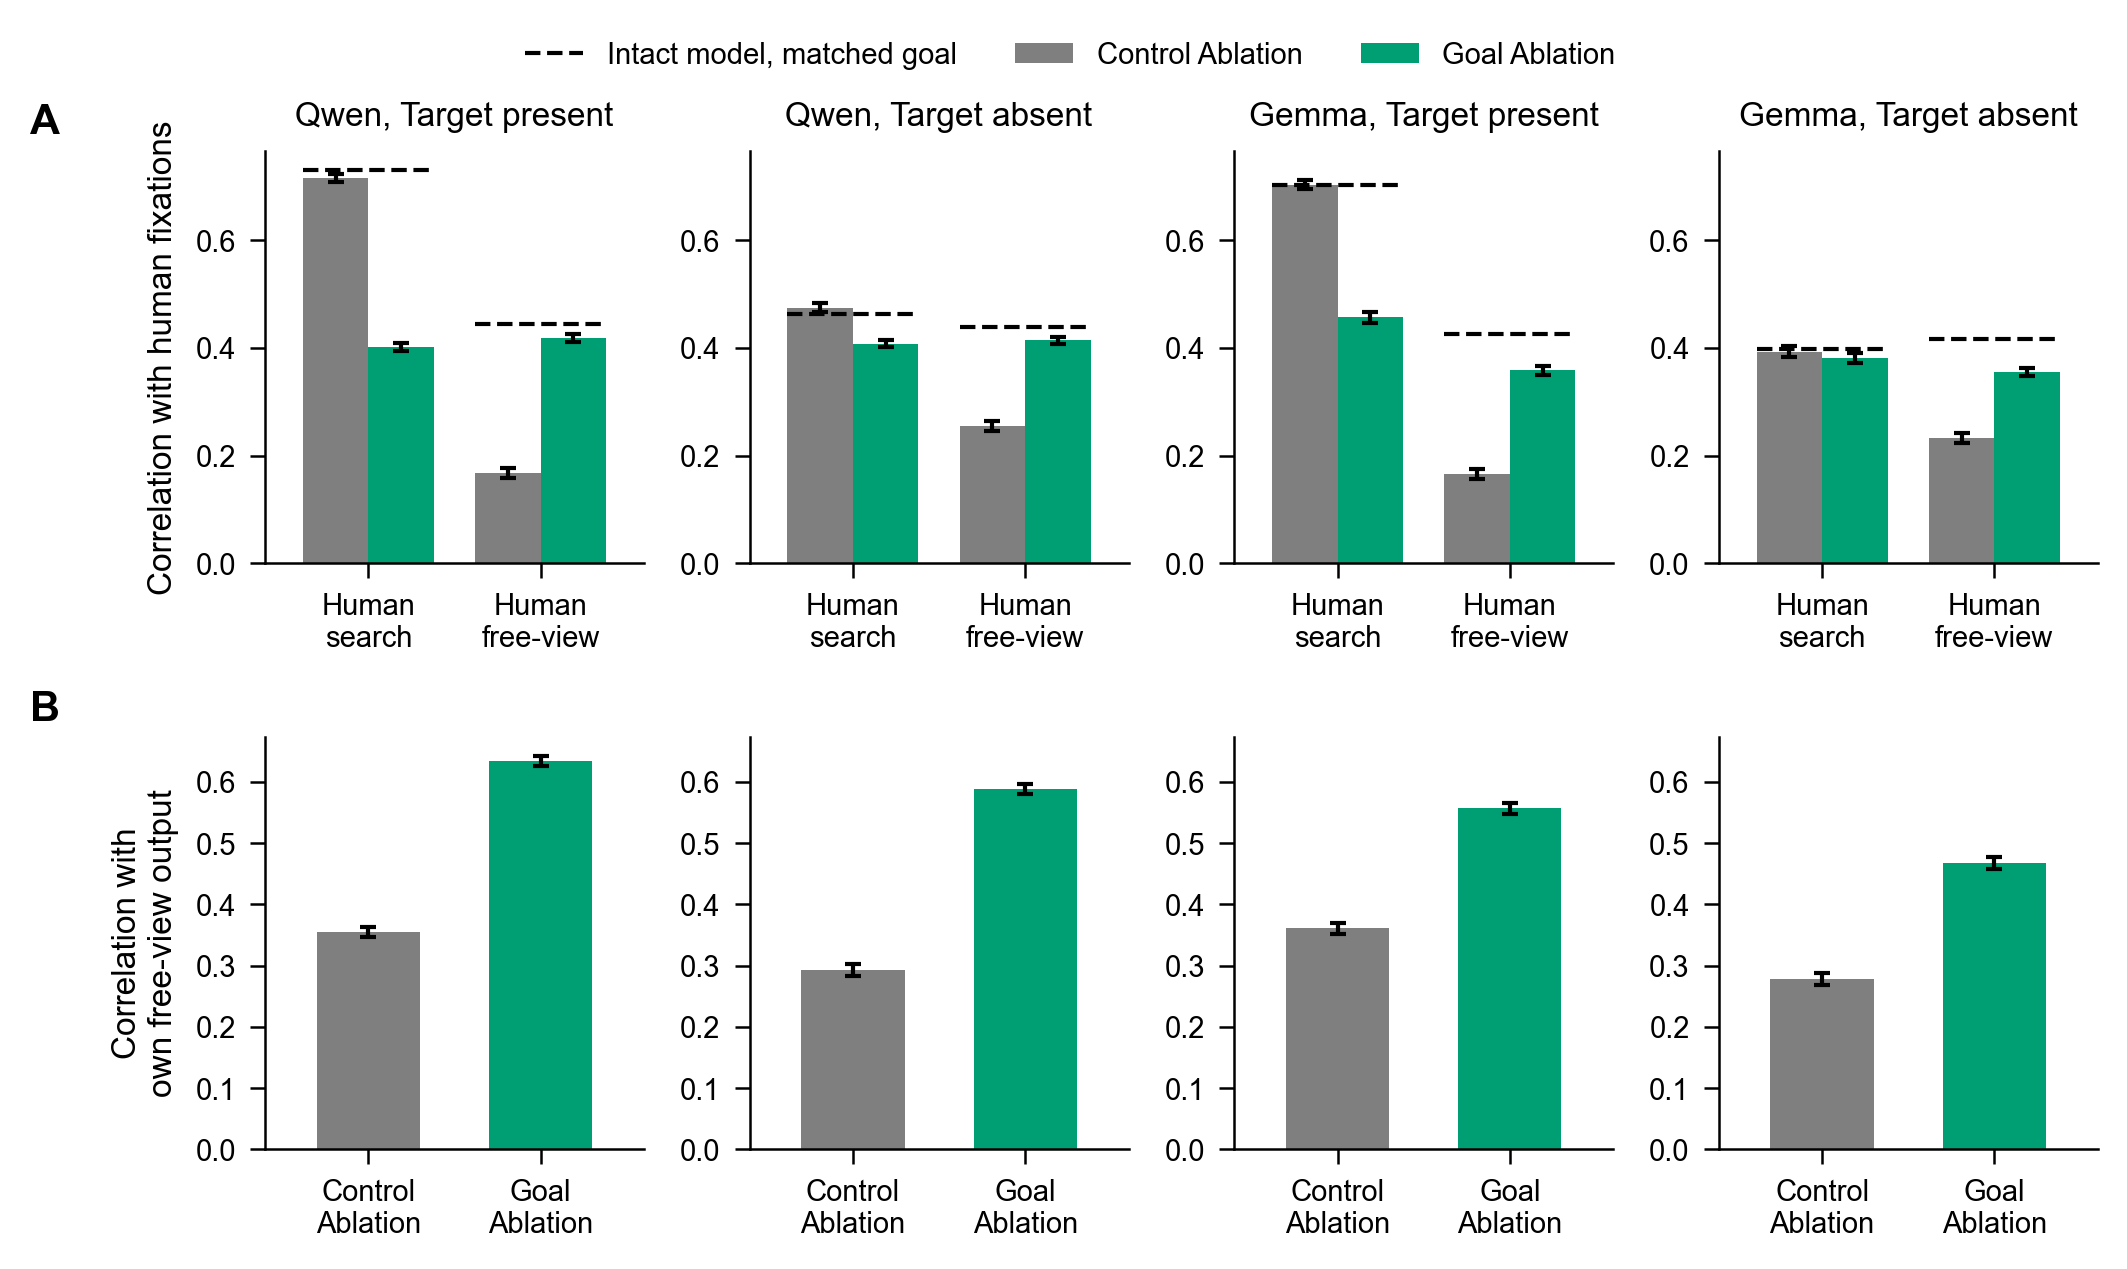

In [19]:
RUN_COLORS = U.ABLATION_COLORS
CELLS = [(model, condition) for model in MODELS for condition in CONDITIONS]

# Intact references from notebook 01 (cell means of the 2x2): (search prompt x human search, free-view prompt x human free-view)
INTACT_REFERENCE = {
    ("qwen-instruct", "tp"): (0.730, 0.444),
    ("qwen-instruct", "ta"): (0.463, 0.439),
    ("gemma", "tp"):         (0.703, 0.426),
    ("gemma", "ta"):         (0.398, 0.417),
}


def mean_ci(values):
    values = values.dropna()
    return values.mean(), stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))


fig, axes = plt.subplots(2, len(CELLS), figsize=(U.DOUBLE_COL, 4.2))
x = np.arange(len(HUMAN_MAPS))
width = 0.38

for col, (model, condition) in enumerate(CELLS):
    cell = scores[(scores["model"] == model) & (scores["condition"] == condition)]
    title = f"{U.MODEL_SHORT[model]}, {U.CONDITION_LABEL[condition]}"

    # ---- A: ablation × human map ----
    ax = axes[0, col]
    for run_index, run in enumerate(ABLATION_RUNS):
        stats_by_map = [mean_ci(cell[cell["run"] == run][metric]) for metric in HUMAN_MAPS]
        ax.bar(x + (run_index - 0.5) * width, [m for m, _ in stats_by_map], width,
               yerr=[c for _, c in stats_by_map], capsize=2, color=RUN_COLORS[run],
               label=run if col == 0 else None)
    for xi, ref in zip(x, INTACT_REFERENCE[(model, condition)]):
        ax.hlines(ref, xi - width, xi + width, color='black', ls="--", lw=1.0,
                  label="Intact model, matched goal" if (col == 0 and xi == 0) else None)
    ax.set_xticks(x)
    ax.set_xticklabels([v.replace(" ", "\n") for v in HUMAN_MAPS.values()])
    ax.set_xlim(-0.6, len(HUMAN_MAPS) - 0.4)
    ax.set_title(title)

    # ---- B: ablation vs the model's own free-view output ----
    ax = axes[1, col]
    for run_index, run in enumerate(ABLATION_RUNS):
        m, c = mean_ci(cell[cell["run"] == run]["vs_freeview"])
        ax.bar(run_index, m, 0.6, yerr=c, capsize=2, color=RUN_COLORS[run])
    ax.set_xticks(range(len(ABLATION_RUNS)))
    ax.set_xticklabels([r.replace(" ", "\n") for r in ABLATION_RUNS])
    ax.set_xlim(-0.6, len(ABLATION_RUNS) - 0.4)

for row in axes:
    lo = min(ax.get_ylim()[0] for ax in row); hi = max(ax.get_ylim()[1] for ax in row)
    for ax in row:
        ax.set_ylim(lo, hi)

axes[0, 0].set_ylabel("Correlation with human fixations")
axes[1, 0].set_ylabel("Correlation with\nown free-view output")
for label, ax in zip("AB", axes[:, 0]):
    ax.text(-0.62, 1.04, label, transform=ax.transAxes, fontsize=10, fontweight="bold")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.96))
ablation_fig = fig